# Самостоятельная работа: RGB DCGAN для лиц Olivetti Faces

В этой работе нужно самостоятельно собрать и исследовать DCGAN для
генерации лиц. Olivetti Faces отличается от LFW: это небольшой набор
из 400 чёрно-белых лиц размером $64\times64$. Канал повторяется три
раза только для совместимости с RGB-архитектурой; новых цветовых
сведений такое преобразование не создаёт.

Все заголовки описывают этапы. Маркеры `TODO(student)` находятся
исключительно в коде и обозначают место самостоятельной реализации.

## Короткий сюжет опыта

Вы строите художника, который рисует лицо по карточке из 100 чисел, и
проверяющего, который отличает рисунок от фотографии. За одну итерацию
сначала учится проверяющий, а затем художник получает его замечания.
Каждая следующая ячейка создаёт одну нужную часть этой игры. Не
переходите дальше, пока контрольная точка текущего этапа не выполнена.

### Словарь перед первой реализацией

Параметры — числа внутри слоёв, которые можно менять. Прямой проход
создаёт картинку и ответ проверяющего. Потеря — одно число, описывающее
ошибку ответа. Градиент — подсказка, как немного изменить параметры.
`GradientTape` находит такие подсказки, а Adam применяет их к выбранной
сети.

## Этап 1. Конфигурация и назначение данных

**Цель:** определить воспроизводимый эксперимент. Доступны все
константы ниже. Метки субъектов Olivetti нельзя передавать в GAN:
генератор не классифицирует людей, а дискриминатор видит только
реальное или синтетическое изображение.

**Контрольная точка:** реальный пакет должен иметь форму
$(B,64,64,3)$, а шум — $(B,100)$.

`(B,64,64,3)` означает «B изображений, у каждого 64 строки, 64
столбца и три канала». Три одинаковых канала здесь нужны не для
создания цвета, а чтобы форма совпадала с учебной RGB-архитектурой.
Метка субъекта — подпись для человека, но не ответ для GAN.

In [1]:
# get_ipython нужен только для Jupyter: эта команда заставляет
# Matplotlib рисовать внутри ноутбука, без отдельного окна Figure.
from __future__ import annotations

from pathlib import Path
from IPython import get_ipython
shell = get_ipython()
if shell is not None:
    shell.run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.datasets import fetch_olivetti_faces

# Сначала зафиксируйте конфигурацию, затем seed — до загрузки и
# создания модели, чтобы срез данных, веса и шум можно было повторить.
SEED = 42
MAX_EXAMPLES = 400
IMAGE_SIZE = 64
CHANNELS = 3
NOISE_DIM = 100
BATCH_SIZE = 32
EPOCHS = 120
LEARNING_RATE = 2e-4
BETA_1 = 0.5
REAL_LABEL = 0.9
# В ARTIFACT_DIR сохраняются только изображения/графики эксперимента.
ARTIFACT_DIR = Path('artifacts/olivetti_face_gan_tensorflow')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

## Этап 2. Получение Olivetti Faces и переход к RGB-форме

**Требуется:** загрузить набор с фиксированным `random_state`, взять
изображения формы $(N,64,64)$, добавить последнюю ось и повторить её
три раза. Затем преобразовать диапазон $[0,1]$ в $[-1,1]$ и создать
`tf.data.Dataset` из изображений без идентификаторов людей.

**Проверка:** `x_real.shape == (MAX_EXAMPLES, 64, 64, 3)`; все
значения конечны и принадлежат $[-1,1]$.

**Сначала → затем → проверить.** Сначала получите серое лицо в
`[0,1]`. Затем повторите канал и получите RGB-форму. После этого
переведите числа в `[-1,1]`: именно в этой шкале будет рисовать `tanh`
генератора. Наконец сформируйте `dataset` только из `x_real`; ID людей
в него не кладётся. Покажите одну картинку до обучения: это быстро
обнаружит перепутанную шкалу или оси.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\perev\scikit_learn_data


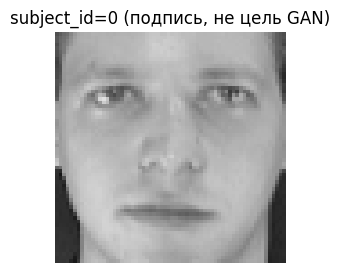

x_real: (400, 64, 64, 3) | диапазон: (-1.0, 1.0)
первый пакет: (32, 64, 64, 3)


In [2]:
# Вход: fetch_olivetti_faces даёт images формы (N,64,64) в [0,1] и
# subject_ids формы (N,). subject_ids можно оставить для подписей,
# однако Dataset обязан содержать только изображения.
# TODO(student): загрузите Olivetti Faces и подготовьте x_real, subject_ids и dataset.
# Повторите единственный серый канал три раза, чтобы получить NHWC
# форму (N,64,64,3), затем примените 2*x-1. После from_tensor_slices
# один элемент dataset имеет (64,64,3), а после batch — (B,64,64,3).
# Проверьте диапазон, конечность и первый пакет до создания сетей.
# TODO(student): объясните в отчёте, почему три одинаковых канала не делают набор цветным.
# raise NotImplementedError('Реализуйте подготовку Olivetti Faces.')

# Загрузка с фиксированным random_state для воспроизводимости.
olivetti = fetch_olivetti_faces(random_state=SEED)

# images: (N,64,64) в [0,1]; subject_ids: (N,) — только для подписей.
x_gray = olivetti.images[:MAX_EXAMPLES].astype("float32")
subject_ids = olivetti.target[:MAX_EXAMPLES]

# (N,64,64) -> (N,64,64,1) -> (N,64,64,3): повторяем серый канал три раза.
x_rgb = np.repeat(x_gray[..., np.newaxis], CHANNELS, axis=-1)

# [0,1] -> [-1,1]: та же шкала, в которой рисует tanh генератора.
x_real = x_rgb * 2.0 - 1.0

# Dataset только из изображений — subject_ids не передаются GAN.
dataset = (
    tf.data.Dataset.from_tensor_slices(x_real)
    .shuffle(buffer_size=MAX_EXAMPLES, seed=SEED)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

# Контрольные проверки.
assert x_real.shape == (MAX_EXAMPLES, IMAGE_SIZE, IMAGE_SIZE, CHANNELS), x_real.shape
assert x_real.dtype == np.float32
assert np.isfinite(x_real).all()
assert x_real.min() >= -1.0 and x_real.max() <= 1.0
first_batch = next(iter(dataset))
assert first_batch.shape == (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS), first_batch.shape
assert first_batch.dtype == tf.float32

# Показ одного лица до обучения: проверка шкалы и осей.
plt.figure(figsize=(3, 3))
plt.imshow((x_real[0] + 1.0) / 2.0)
plt.title(f"subject_id={subject_ids[0]} (подпись, не цель GAN)")
plt.axis("off")
plt.show()

print("x_real:", x_real.shape, "| диапазон:", (float(x_real.min()), float(x_real.max())))
print("первый пакет:", first_batch.shape)

## Этап 3. Свёрточный генератор

**Требуется:** реализовать генератор, который преобразует
$(B,100)$ в $(B,64,64,3)$: `Dense(4·4·512)`, reshape и четыре
`Conv2DTranspose` с промежуточными BatchNormalization и ReLU. На
последнем слое используйте `tanh`.

**Контрольная точка:** диагностический проход выдаёт конечные значения
в диапазоне $[-1,1]$, а не плоский вектор пикселей.

Генератор сначала получает одну карточку из 100 чисел на лицо. Он
делает маленькую внутреннюю картинку, а затем несколько раз увеличивает
её. Транспонированная свёртка — не волшебное увеличение готовой
фотографии: она применяет обучаемые правила и создаёт новые пиксели.
`BatchNormalization` помогает числам внутри сети оставаться удобного
масштаба, а `tanh` ограничивает финальные RGB-значения.

In [3]:
# make_generator создаёт θ_G и не обучает их. Для z=(B,100) DCGAN
# должен сначала получить карту 4×4×512, затем увеличивать H и W
# транспонированными свёртками 4→8→16→32→64 и закончить tanh.
# TODO(student): реализуйте make_generator и постройте generator.
# Диагностика: вызов G(z, training=False) возвращает (B,64,64,3).
# training=False здесь нужен для чистой проверки BatchNorm; он не
# заменяет GradientTape в дальнейшем обучении.
# TODO(student): проверьте форму G(z) для z формы (BATCH_SIZE, NOISE_DIM).
# raise NotImplementedError('Реализуйте генератор DCGAN.')

def make_generator(seed: int = SEED) -> tf.keras.Model:
    initializer = tf.keras.initializers.RandomNormal(stddev=0.02, seed=seed)
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(NOISE_DIM,)),
            # 100 -> 4*4*512 (без bias: его роль берёт BatchNorm).
            tf.keras.layers.Dense(4 * 4 * 512, use_bias=False, kernel_initializer=initializer),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.ReLU(),
            tf.keras.layers.Reshape((4, 4, 512)),
            # 4 -> 8
            tf.keras.layers.Conv2DTranspose(256, 4, strides=2, padding="same", use_bias=False, kernel_initializer=initializer),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.ReLU(),
            # 8 -> 16
            tf.keras.layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False, kernel_initializer=initializer),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.ReLU(),
            # 16 -> 32
            tf.keras.layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False, kernel_initializer=initializer),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.ReLU(),
            # 32 -> 64, финальный tanh: диапазон [-1,1], как у реальных данных.
            tf.keras.layers.Conv2DTranspose(CHANNELS, 4, strides=2, padding="same", activation="tanh", kernel_initializer=initializer),
        ],
        name="generator",
    )


generator = make_generator()

# Диагностический проход без GradientTape.
z_check = tf.random.normal((BATCH_SIZE, NOISE_DIM), seed=SEED)
generated_check = generator(z_check, training=False)

assert generated_check.shape == (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS), generated_check.shape
assert np.isfinite(generated_check.numpy()).all()
assert float(tf.reduce_min(generated_check)) >= -1.0 and float(tf.reduce_max(generated_check)) <= 1.0
print("G(z):", generated_check.shape, "| диапазон:", (float(tf.reduce_min(generated_check)), float(tf.reduce_max(generated_check))))

G(z): (32, 64, 64, 3) | диапазон: (-0.01722053997218609, 0.01982152834534645)


## Этап 4. Свёрточный дискриминатор и логиты

**Требуется:** собрать дискриминатор из свёрток со stride 2,
LeakyReLU, Dropout и завершающего `Dense(1)` **без sigmoid**. Его
выход — логит формы $(B,1)$. Поэтому в BCE надо указать
`from_logits=True`.

**Контрольная точка:** не проверяйте логиты на принадлежность
интервалу $(0,1)$: это свойство вероятности после sigmoid, но не
самого логита.

Логит — просто оценка до перевода в вероятность. Большой положительный
логит говорит «скорее настоящее», большой отрицательный — «скорее
синтетическое». `BinaryCrossentropy(from_logits=True)` сама выполняет
нужный перевод надёжнее, чем отдельный sigmoid. D не определяет, кто
изображён на лице: он отвечает только на вопрос об источнике картинки.

In [4]:
# D принимает NHWC-карту (B,64,64,3) и четырьмя Conv2D со stride=2
# сжимает её до признаков 4×4. Последний Dense возвращает логит (B,1)
# БЕЗ sigmoid, поэтому BCE должно получить from_logits=True.
# TODO(student): реализуйте make_discriminator и проверьте форму D(x).
# Создайте два независимых Adam: их внутренние моменты относятся к
# разным параметрам θ_G и θ_D и не могут быть общими.
# TODO(student): создайте BinaryCrossentropy(from_logits=True) и два Adam-оптимизатора.
# raise NotImplementedError('Реализуйте дискриминатор и функции потерь.')

def make_discriminator(seed: int = SEED) -> tf.keras.Model:
    initializer = tf.keras.initializers.RandomNormal(stddev=0.02, seed=seed)
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)),
            # 64 -> 32
            tf.keras.layers.Conv2D(64, 4, strides=2, padding="same", kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            # 32 -> 16
            tf.keras.layers.Conv2D(128, 4, strides=2, padding="same", kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            # 16 -> 8
            tf.keras.layers.Conv2D(256, 4, strides=2, padding="same", kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            # 8 -> 4
            tf.keras.layers.Conv2D(512, 4, strides=2, padding="same", kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Flatten(),
            # Логит (B,1): без sigmoid, from_logits=True в BCE.
            tf.keras.layers.Dense(1, kernel_initializer=initializer),
        ],
        name="discriminator",
    )


discriminator = make_discriminator()

# Диагностика: один реальный и один синтетический пакет.
real_check = next(iter(dataset))
fake_check = generator(tf.random.normal((BATCH_SIZE, NOISE_DIM), seed=SEED + 1), training=False)
real_logits_check = discriminator(real_check, training=False)
fake_logits_check = discriminator(fake_check, training=False)

assert real_logits_check.shape == (BATCH_SIZE, 1), real_logits_check.shape
assert fake_logits_check.shape == (BATCH_SIZE, 1), fake_logits_check.shape
assert np.isfinite(real_logits_check.numpy()).all()
assert np.isfinite(fake_logits_check.numpy()).all()
# Не проверяем логиты на (0,1): это свойство вероятности, а не логита.
print("D(x_real):", real_logits_check.shape, "| D(x_fake):", fake_logits_check.shape)

# from_logits=True: D отдаёт логиты, sigmoid объединён с BCE устойчиво.
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# Два независимых Adam: состояния моментов G и D не смешиваются.
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)

D(x_real): (32, 1) | D(x_fake): (32, 1)


## Этап 5. Раздельные шаги оптимизации

**Требуется:** реализовать два `GradientTape`. В шаге дискриминатора
используйте `stop_gradient(G(z))`, реальные цели 0.9 и синтетические
0. В шаге генератора используйте новую выборку шума и целевое значение
1; градиент должен пройти через дискриминатор к изображению, но
оптимизатор меняет только переменные генератора.

**Проверка:** обе потери — конечные скаляры; после каждого подшага
изменяется только соответствующий набор параметров.

**Сначала учится D.** Настоящие лица имеют цель 0.9, рисунки — 0.
`stop_gradient` превращает рисунок в «готовую картинку» именно для
этой фазы: обратная стрелка к G выключена. **Затем учится G.** Новый
шум создаёт новый рисунок, а его цель равна 1. D остаётся полезным
проверяющим, который сообщает направление улучшения, но второй
оптимизатор получает только веса G.

`training=False` у D означает «не включать его Dropout», а не «не
передавать замечание художнику». Стрелка градиента к G сохраняется;
она исчезла бы только при `stop_gradient` в этой второй фазе.

Здесь D возвращает логит $\ell$, то есть свободную оценку до
вероятности. Мысленно вероятность равна
$p=\sigma(\ell)=1/(1+e^{-\ell})$, а ошибка одной картинки и цели $y$
записывается так:

$$
\operatorname{BCE}(y,p)=-y\log p-(1-y)\log(1-p).
$$

`BinaryCrossentropy(from_logits=True)` получает логит и объединяет
sigmoid с этой формулой устойчиво; отдельный sigmoid перед loss был бы
неверным дублированием.

### Математический и API-контракт

**Сначала прочитайте маршрут одного пакета, а уже потом заполняйте
`TODO(student)`.**

![Два независимых обновления GAN: обучение дискриминатора, затем обучение генератора](assets/diagrams/gan_two_phase_training.svg)

На рисунке синие блоки — данные, зелёные — сети с параметрами, красные
— потери-скаляры. Ваш код будет создавать временные синие тензоры,
получать два красных числа и передавать Adam только пары градиентов с
зелёными параметрами. Ни шум, ни изображения, ни классовые метки лиц
не являются объектами оптимизации.

Пусть $\theta_G$ — все веса генератора, а $\theta_D$ — все веса
дискриминатора. Потеря — одно итоговое число. Её производная по весу
отвечает, в какую сторону слегка изменить этот вес; общий шаг имеет вид

$$
\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L.
$$

В первой фазе составьте $\mathcal L_D$ из BCE настоящих лиц с целью
0.9 и синтетических с целью 0, после чего берите градиент только по
$\theta_D$. Во второй составьте
$\mathcal L_G=\operatorname{BCE}(1,D(G(\mathbf z_G)))$ и берите
градиент только по $\theta_G$. Шум $\mathbf z_G$ — новый вход, а не
параметр, который оптимизатор должен сохранять.

### Как `GradientTape` помогает выполнить математическое правило

![Жизненный цикл GradientTape от прямого прохода до обновления Adam](assets/diagrams/tensorflow_gradient_tape.svg)

`GradientTape` записывает прямой путь до одной потери. Пока активен
блок `with`, TensorFlow строит временный граф дифференцируемых операций
и автоматически наблюдает задействованные обучаемые `tf.Variable`.
Вызов `tape.gradient(loss, variables)` идёт по этому графу назад и
возвращает одну производную на каждый указанный вес; её форма совпадает
с формой этого веса. Наконец, `zip` формирует пары «производная, вес»,
а `apply_gradients` передаёт их Adam. Поэтому именно список переменных
в этом вызове определяет, что обновляется.

У обычного непостоянного tape есть один обратный проход: после
`gradient(...)` его запись освобождается. Не нужно вручную строить
якобианы всех RGB-пикселей и весов; TensorFlow эффективно передаёт их
действие на градиент скалярной потери.

В фазе G путь остаётся математически равным

$$
\frac{\partial\mathcal L_G}{\partial\theta_G}
=\frac{\partial\mathcal L_G}{\partial D}
\frac{\partial D}{\partial G}
\frac{\partial G}{\partial\theta_G}.
$$

Это **цепное правило**: изменение веса G меняет картинку, картинка
меняет ответ D, а ответ D меняет итоговую потерю. D участвует в этой
цепочке как измерительный прибор, но его веса не стоят в списке
`variables`, поэтому их поправка не применяется.

### Один мини-пакет: спецификация будущего TensorFlow-кода

В самостоятельной реализации используйте следующие математические
роли и имена. Ничего из этой таблицы не надо оптимизировать, кроме
параметров $\theta_G$ и $\theta_D$.

| Объект | Имя, которое следует завести | Форма | Что проверять |
| --- | --- | --- | --- |
| Настоящие лица $\mathbf x_{\rm real}$ | `real_images` | `(B,64,64,3)` | Значения `[-1,1]`, цель D — 0.9. |
| Шум D $\mathbf z_D$ | `discriminator_noise` | `(B,100)` | Это временный вход генератора. |
| Подделка для D | `fake_images` | `(B,64,64,3)` | После `stop_gradient`; цель D — 0. |
| Логиты D | `real_logits`, `fake_logits` | `(B,1)` | Могут быть любыми вещественными числами. |
| Потеря D | `d_loss` | скаляр | Градиент берётся по `discriminator.trainable_variables`. |
| Шум G $\mathbf z_G$ | `generator_noise` | `(B,100)` | Это новая независимая выборка. |
| Изображение G | `generated_images` | `(B,64,64,3)` | Не отсоединяется от графа. |
| Потеря G | `g_loss` | скаляр | Градиент берётся по `generator.trainable_variables`. |

**Контроль перед переходом к следующей ячейке.** Разделите в уме
объекты таблицы на данные, параметры и скаляры. `fake_images` после
`stop_gradient` всё ещё имеет форму `(B,64,64,3)` и те же пиксели, но
перестаёт быть путём к $\theta_G$ только в фазе D. Во второй фазе
`generated_images` нельзя отсоединять: иначе `g_loss` не сможет дать
генератору никакого замечания.

**Порядок, который надо увидеть в своём коде.** Сначала первый tape
должен закончиться `d_loss`; следующий вызов `gradient` получает только
список весов D. Потом создаётся второй tape и новый шум; он заканчивается
`g_loss`, а `gradient` получает только список весов G. `zip` не меняет
данные — он лишь соединяет производную правильной формы с её весом.
Только `apply_gradients` делает шаг Adam и действительно изменяет сеть.

Для проверки обратного пути используйте запись

$$
\nabla_{\theta_G}\mathcal L_G=
J_{G,\theta_G}^{\mathsf T}J_{D,\mathbf x}^{\mathsf T}
\nabla_{\ell}\mathcal L_G.
$$

Якобиан — таблица локальных влияний. TensorFlow не материализует
огромные якобианы для RGB-изображений, а вычисляет их нужное действие
на градиент ошибки автоматически во время `tape.gradient`.

In [5]:
# train_step принимает real_images=(B,64,64,3) и возвращает два
# конечных скаляра. Фаза D: z_D→G(z_D,training=False)→stop_gradient,
# затем BCE D(real) с целью 0.9 и BCE D(fake) с целью 0. Получайте
# tape.gradient только по discriminator.trainable_variables.
# Фаза G: новый z_G→G(z_G,training=True)→D(...,training=False), BCE с
# целью 1. training=False у D выключает Dropout, но НЕ препятствует
# цепочке градиента от loss к пикселям и параметрам генератора.
# TODO(student): реализуйте train_step и убедитесь в раздельном применении градиентов.
# Контроль: в первой фазе D обновляется, G — нет; во второй обновляется
# G. Нельзя применять stop_gradient во второй фазе, иначе G не получит
# обучающий сигнал. В apply_gradients передавайте пары только своей сети.
# raise NotImplementedError('Реализуйте попеременное обучение DCGAN.')

@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]

    # ---------- Фаза D: обновляем только θ_D ----------
    discriminator_noise = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as disc_tape:
        # stop_gradient: обратная стрелка к G в фазе D выключена.
        fake_images = tf.stop_gradient(generator(discriminator_noise, training=False))

        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)

        real_loss = bce(tf.fill((batch_size, 1), REAL_LABEL), real_logits)
        fake_loss = bce(tf.fill((batch_size, 1), 0.0), fake_logits)
        d_loss = 0.5 * (real_loss + fake_loss)

    d_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))

    # ---------- Фаза G: обновляем только θ_G ----------
    generator_noise = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as gen_tape:
        generated_images = generator(generator_noise, training=True)
        # training=False выключает Dropout D, но НЕ обрывает градиент к G.
        generated_logits = discriminator(generated_images, training=False)
        g_loss = bce(tf.fill((batch_size, 1), 1.0), generated_logits)

    g_grads = gen_tape.gradient(g_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))

    return d_loss, g_loss


# Контроль: один шаг на реальном пакете, потери — конечные скаляры.
sample_batch = next(iter(dataset))
d_loss, g_loss = train_step(sample_batch)
assert np.isfinite(d_loss.numpy()) and np.isfinite(g_loss.numpy())
assert d_loss.shape == () and g_loss.shape == ()
print(f"один шаг: L_D={float(d_loss):.4f}, L_G={float(g_loss):.4f}")

# Дополнительный контроль раздельности обновлений.
def snapshot(variables):
    return [v.numpy().copy() for v in variables]

g_before = snapshot(generator.trainable_variables)
d_before = snapshot(discriminator.trainable_variables)
train_step(next(iter(dataset)))
g_after = snapshot(generator.trainable_variables)
d_after = snapshot(discriminator.trainable_variables)

assert any(not np.array_equal(b, a) for b, a in zip(g_before, g_after))
assert any(not np.array_equal(b, a) for b, a in zip(d_before, d_after))
print("оба набора параметров изменились; в фазах D/G обновлялись разные списки переменных")

один шаг: L_D=0.6875, L_G=0.6150
оба набора параметров изменились; в фазах D/G обновлялись разные списки переменных


## Этап 6. Наблюдение генераций и выводы

**Требуется:** обучить DCGAN, сохранять сетку фиксированных шумовых
векторов через равные интервалы, построить обе истории потерь и
объяснить разнообразие либо коллапс мод. Не считайте идентификаторы
людей показателем качества GAN.

**Итоговая самопроверка:** шум `(B,100)`, изображения `(B,64,64,3)`,
логиты `(B,1)`, значения потерь конечны, метки субъектов не участвовали
в обучении.

Используйте один `fixed_noise` для всех сеток. Это одинаковые задания
для художника в начале и конце опыта; тогда видна работа обучения, а
не смена карточки. Для вывода на экран верните `[-1,1]` к `[0,1]`.
Линии потерь — полезный дневник, но не оценка красоты: смотрите на них
вместе с разнообразием лиц и отсутствием чёрных/одинаковых кадров.

эпоха   1/120 | L_D=0.5112 | L_G=0.1351
эпоха  10/120 | L_D=0.1667 | L_G=0.0665
эпоха  20/120 | L_D=0.1802 | L_G=0.0186
эпоха  30/120 | L_D=0.5777 | L_G=1.5636
эпоха  40/120 | L_D=0.4557 | L_G=0.6887
эпоха  50/120 | L_D=0.7571 | L_G=1.2934
эпоха  60/120 | L_D=0.5811 | L_G=0.9956
эпоха  70/120 | L_D=0.5232 | L_G=0.8163
эпоха  80/120 | L_D=0.4611 | L_G=0.6562
эпоха  90/120 | L_D=0.4647 | L_G=0.3946
эпоха 100/120 | L_D=0.4437 | L_G=0.9099
эпоха 110/120 | L_D=0.5793 | L_G=0.8814
эпоха 120/120 | L_D=0.3247 | L_G=0.2901


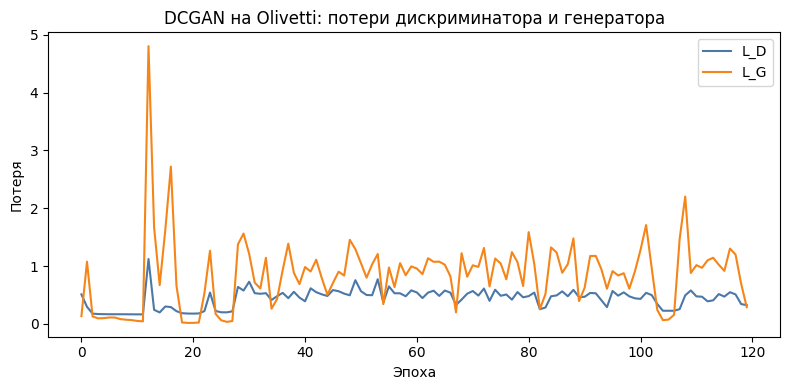

Сохранено в: artifacts\olivetti_face_gan_tensorflow


In [6]:
# Цикл эпох перебирает dataset и собирает скаляры из train_step.
# Усредляйте их по всем пакетам; fixed_noise=(64,100) создайте один
# раз вне цикла, чтобы последующие сетки показывали изменение весов,
# а не новый случайный вход. Для изображения верните [-1,1] в [0,1].
# TODO(student): реализуйте цикл эпох, сохранение сеток и график потерь.
# raise NotImplementedError('Завершите эксперимент и подготовьте выводы.')

# Фиксированный шум создаётся один раз: одинаковые задания художнику.
fixed_noise = tf.random.normal((64, NOISE_DIM), seed=SEED)


def make_grid(model, noise, path):
    samples = model(noise, training=False)
    samples = (samples + 1.0) / 2.0  # [-1,1] -> [0,1]
    samples = np.clip(samples.numpy(), 0.0, 1.0)
    fig, axes = plt.subplots(8, 8, figsize=(10, 10))
    for i, ax in enumerate(axes.flat):
        ax.imshow(samples[i])
        ax.axis("off")
    fig.suptitle(f"Olivetti DCGAN, {path.stem}")
    fig.tight_layout()
    fig.savefig(path, dpi=110)
    plt.close(fig)


def run_experiment(epochs: int):
    # Полный перезапуск: новые веса и оптимизаторы.
    tf.keras.utils.set_random_seed(SEED)
    global generator, discriminator, generator_optimizer, discriminator_optimizer, bce
    generator = make_generator()
    discriminator = make_discriminator()
    bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)
    generator_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)
    discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, beta_1=BETA_1)

    history = {"d_loss": [], "g_loss": []}
    for epoch in range(1, epochs + 1):
        d_epoch, g_epoch = [], []
        for real_batch in dataset:
            d_loss, g_loss = train_step(real_batch)
            d_epoch.append(float(d_loss))
            g_epoch.append(float(g_loss))
        history["d_loss"].append(float(np.mean(d_epoch)))
        history["g_loss"].append(float(np.mean(g_epoch)))

        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            make_grid(generator, fixed_noise, ARTIFACT_DIR / f"grid_epoch_{epoch:03d}.png")
            print(f"эпоха {epoch:3d}/{epochs} | L_D={history['d_loss'][-1]:.4f} | L_G={history['g_loss'][-1]:.4f}")

    assert all(np.isfinite(v) for v in history["d_loss"] + history["g_loss"])
    return history


history = run_experiment(EPOCHS)

# График двух потерь.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["d_loss"], label="L_D", color="#4c78a8")
ax.plot(history["g_loss"], label="L_G", color="#f58518")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Потеря")
ax.set_title("DCGAN на Olivetti: потери дискриминатора и генератора")
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "loss_curves.png", dpi=110)
plt.show()

print("Сохранено в:", ARTIFACT_DIR)